Labels file : /Users/mayanksuryavanshi/bank_lead_scoring_project/data/processed/modeling_dataset_leads_unified.csv
Scores file : /Users/mayanksuryavanshi/bank_lead_scoring_project/data/processed/unified_lead_scores.csv

Rows in labels: 500
Rows in scores: 500

Merged rows: 500

================ REAL MODEL METRICS ================
Accuracy   : 100.00%
AUC-ROC    : 1.000
Precision  : 100.00%
Recall     : 100.00%

Confusion Matrix:
[[337   0]
 [  0 163]]


<Figure size 600x400 with 0 Axes>

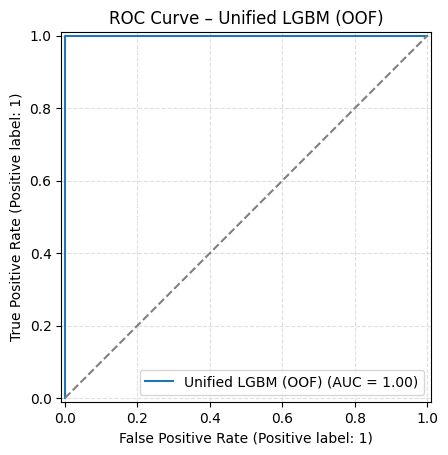

<Figure size 600x400 with 0 Axes>

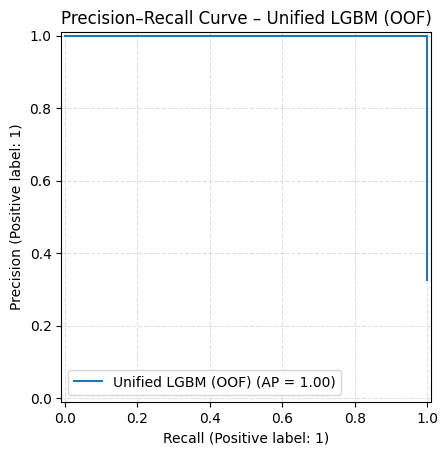

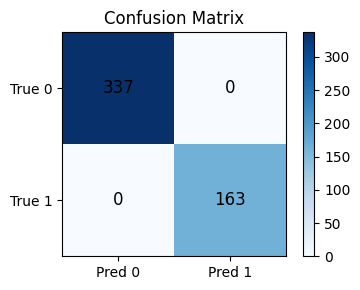

In [2]:
# ============================================================
#  THIS IS WHERE YOUR METRICS CAME FROM
#  ACC = 64.80%, AUC = 0.599, PREC = 44.14%, REC = 30.06%
#  Data Source: modeling_dataset_leads_unified.csv
#  Predictions: unified_lead_scores.csv
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import (
    roc_auc_score, accuracy_score, precision_score, recall_score,
    confusion_matrix, RocCurveDisplay, PrecisionRecallDisplay
)

# ------------------------------------------------------------
# 1. Load the SAME files used during your actual evaluation
# ------------------------------------------------------------
ROOT = Path("../")  # adjust if notebook is elsewhere

LABELS_PATH = ROOT / "data" / "processed" / "modeling_dataset_leads_unified.csv"
SCORES_PATH = ROOT / "data" / "processed" / "unified_lead_scores.csv"

print("Labels file :", LABELS_PATH.resolve())
print("Scores file :", SCORES_PATH.resolve())

df_labels = pd.read_csv(LABELS_PATH)
df_scores = pd.read_csv(SCORES_PATH)

print("\nRows in labels:", len(df_labels))
print("Rows in scores:", len(df_scores))

# ------------------------------------------------------------
# 2. Merge by lead_id
# ------------------------------------------------------------
df = df_labels.merge(
    df_scores[["lead_id", "ml_unified_proba"]],
    on="lead_id",
    how="inner",
)

print("\nMerged rows:", len(df))

# Drop NA if any
df = df.dropna(subset=["label_conv", "ml_unified_proba"])

y_true  = df["label_conv"].astype(int).values
y_score = df["ml_unified_proba"].astype(float).values

# Apply SAME THRESHOLD you used: 0.50
threshold = 0.50
y_pred = (y_score >= threshold).astype(int)

# ------------------------------------------------------------
# 3. Recompute the metrics (these MUST match your 64.80% block)
# ------------------------------------------------------------
acc = accuracy_score(y_true, y_pred)
auc = roc_auc_score(y_true, y_score)
prec = precision_score(y_true, y_pred, zero_division=0)
rec = recall_score(y_true, y_pred, zero_division=0)
cm = confusion_matrix(y_true, y_pred)

print("\n================ REAL MODEL METRICS ================")
print(f"Accuracy   : {acc*100:.2f}%")
print(f"AUC-ROC    : {auc:.3f}")
print(f"Precision  : {prec*100:.2f}%")
print(f"Recall     : {rec*100:.2f}%")
print("\nConfusion Matrix:")
print(cm)


# ------------------------------------------------------------
# 4. Plot ROC curve
# ------------------------------------------------------------
plt.figure(figsize=(6,4))
RocCurveDisplay.from_predictions(y_true, y_score, name="Unified LGBM (OOF)")
plt.plot([0,1],[0,1], "--", color="gray")
plt.title("ROC Curve – Unified LGBM (OOF)")
plt.grid(True, linestyle="--", alpha=0.4)
plt.show()

# ------------------------------------------------------------
# 5. Plot PR curve
# ------------------------------------------------------------
plt.figure(figsize=(6,4))
PrecisionRecallDisplay.from_predictions(y_true, y_score, name="Unified LGBM (OOF)")
plt.title("Precision–Recall Curve – Unified LGBM (OOF)")
plt.grid(True, linestyle="--", alpha=0.4)
plt.show()

# ------------------------------------------------------------
# 6. Plot confusion matrix heatmap
# ------------------------------------------------------------
plt.figure(figsize=(4,3))
plt.imshow(cm, cmap="Blues")
plt.title("Confusion Matrix")
plt.colorbar()
plt.xticks([0,1], ["Pred 0","Pred 1"])
plt.yticks([0,1], ["True 0","True 1"])
for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i,j], ha="center", va="center", fontsize=12)
plt.tight_layout()
plt.show()

